In [1]:
import numpy as np
import pandas as pd
import pickle
import xgboost as xgb
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load features from the CamemBERT extraction
print("Loading pre-extracted features...")

with open('features.pkl', 'rb') as f:
    data = pickle.load(f)

X_train_full = data['X_train']
y_train_full = data['y_train']
X_kaggle = data['X_kaggle']
kaggle_ids = data['kaggle_ids']

print(f"✓ Features loaded")
print(f"  Train: {X_train_full.shape}")
print(f"  Kaggle: {X_kaggle.shape}")
print(f"  Features: {X_train_full.shape[1]}")
print(f"\nClass distribution:")
unique, counts = np.unique(y_train_full, return_counts=True)
for label, count in zip(unique, counts):
    print(f"  Class {label}: {count} ({count/len(y_train_full)*100:.2f}%)")
    


Loading pre-extracted features...
✓ Features loaded
  Train: (154914, 3075)
  Kaggle: (103380, 3075)
  Features: 3075

Class distribution:
  Class 0: 82674 (53.37%)
  Class 1: 72240 (46.63%)


AttributeError: 'numpy.ndarray' object has no attribute 'collumns'

---
## 3. Configure XGBoost

These parameters are a good starting point. You can tune them later.

In [ ]:
# XGBoost parameters
params = {
    # Model complexity
    'max_depth': 4,              # Maximum tree depth
    'min_child_weight': 1,       # Minimum sum of instance weight needed in a child
    'gamma': 0,                  # Minimum loss reduction required to make a split
    
    # Regularization
    'reg_alpha': 0,              # L1 regularization
    'reg_lambda': 1,             # L2 regularization
    
    # Training
    'learning_rate': 0.1,        # Step size shrinkage (eta)
    'n_estimators': 500,         # Number of boosting rounds
    
    # Sampling
    'subsample': 0.8,            # Fraction of samples for each tree
    'colsample_bytree': 0.8,     # Fraction of features for each tree
    
    # Other
    'objective': 'binary:logistic',
    'eval_metric': 'logloss',
    'tree_method': 'auto',  # ← Change this for GPU
    'device': 'cuda',
    'random_state': 42,
    'n_jobs': -1                 # Use all CPU cores
}

print("XGBoost Configuration:")
for key, value in params.items():
    print(f"  {key}: {value}")

XGBoost Configuration:
  max_depth: 4
  min_child_weight: 1
  gamma: 0
  reg_alpha: 0
  reg_lambda: 1
  learning_rate: 0.1
  n_estimators: 500
  subsample: 0.8
  colsample_bytree: 0.8
  objective: binary:logistic
  eval_metric: logloss
  tree_method: auto
  device: cuda
  random_state: 42
  n_jobs: -1


---
## 5. Train XGBoost Model on Full Training Data

In [21]:
print("\nTraining XGBoost model on full training data...")
print("="*70)

# Initialize model
model = xgb.XGBClassifier(**params)

# Train on full dataset
model.fit(
    X_train_full, y_train_full,
    verbose=10  # Print every 50 rounds
)

# Check training accuracy
y_pred_train = model.predict(X_train_full)
train_acc = accuracy_score(y_train_full, y_pred_train)

print("\n" + "="*70)
print(f"✓ Training complete!")
print(f"  Training Accuracy: {train_acc*100:.2f}%")
print("="*70)


Training XGBoost model on full training data...

✓ Training complete!
  Training Accuracy: 92.13%


---
## 6. Training Metrics

In [22]:
# Check training performance
print("\nTraining Set Performance:")
print(f"  Accuracy: {train_acc*100:.2f}%")

print("\nTraining Classification Report:")
print(classification_report(y_train_full, y_pred_train, target_names=['Class 0', 'Class 1']))

print("\n⚠️ Note: True performance will be measured on Kaggle leaderboard")
print("   Training accuracy is just for reference (may overfit)")


Training Set Performance:
  Accuracy: 92.13%

Training Classification Report:
              precision    recall  f1-score   support

     Class 0       0.91      0.95      0.93     82674
     Class 1       0.94      0.89      0.91     72240

    accuracy                           0.92    154914
   macro avg       0.92      0.92      0.92    154914
weighted avg       0.92      0.92      0.92    154914


⚠️ Note: True performance will be measured on Kaggle leaderboard
   Training accuracy is just for reference (may overfit)


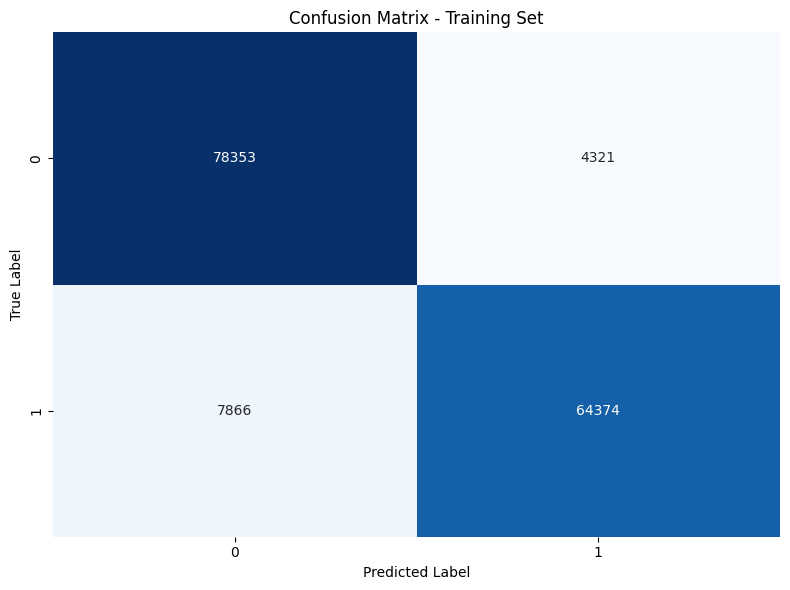

✓ Confusion matrix saved to 'confusion_matrix.png'


In [23]:
# Confusion Matrix (on training data)
cm = confusion_matrix(y_train_full, y_pred_train)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix - Training Set')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150)
plt.show()

print("✓ Confusion matrix saved to 'confusion_matrix.png'")

---
## 7. Feature Importance (Optional)

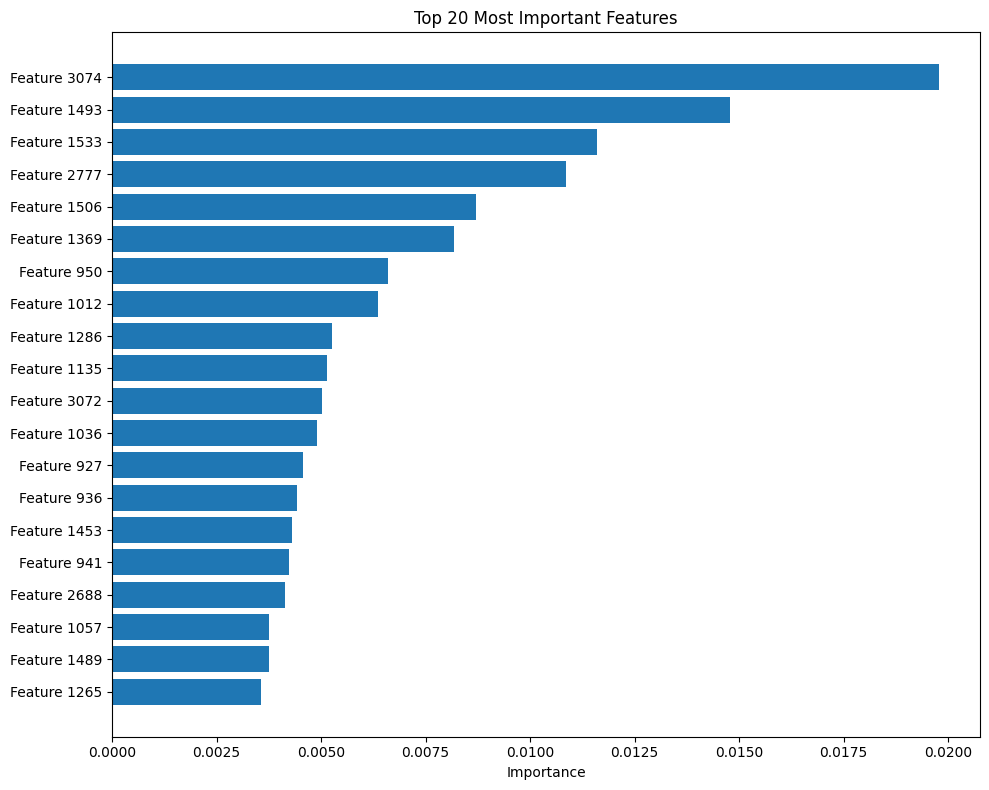

✓ Feature importance plot saved to 'feature_importance.png'

Most important feature: Feature 3074 (importance: 0.0198)


In [24]:
# Get feature importance
importance = model.feature_importances_

# Top 20 most important features
top_indices = np.argsort(importance)[-20:]

plt.figure(figsize=(10, 8))
plt.barh(range(20), importance[top_indices])
plt.yticks(range(20), [f'Feature {i}' for i in top_indices])
plt.xlabel('Importance')
plt.title('Top 20 Most Important Features')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150)
plt.show()

print(f"✓ Feature importance plot saved to 'feature_importance.png'")
print(f"\nMost important feature: Feature {top_indices[-1]} (importance: {importance[top_indices[-1]]:.4f})")

---
## 8. Generate Predictions for Kaggle

In [25]:
print("\nGenerating predictions for Kaggle test set...")

# Predict on Kaggle test set
y_pred_kaggle = model.predict(X_kaggle)

print(f"✓ Predictions generated")
print(f"\nPrediction distribution:")
unique, counts = np.unique(y_pred_kaggle, return_counts=True)
for label, count in zip(unique, counts):
    print(f"  Class {label}: {count} ({count/len(y_pred_kaggle)*100:.2f}%)")


Generating predictions for Kaggle test set...
✓ Predictions generated

Prediction distribution:
  Class 0: 56848 (54.99%)
  Class 1: 46532 (45.01%)


In [26]:
# Create submission file
submission = pd.DataFrame({
    'ID': kaggle_ids,
    'Prediction': y_pred_kaggle
})

submission.to_csv('xgboost_predictions.csv', index=False)

print("\n✓ Predictions saved to 'xgboost_predictions.csv'")
print(f"\nSubmission file preview:")
print(submission.head(10))


✓ Predictions saved to 'xgboost_predictions.csv'

Submission file preview:
   ID  Prediction
0   0           1
1   2           1
2   4           0
3   8           1
4   9           0
5  10           0
6  13           0
7  14           0
8  15           1
9  19           0


---
## 10. Save Model (Optional)

In [ ]:
# Save the trained model
model.save_model('xgboost_model.json')
print("✓ Model saved to 'xgboost_model.json'")

# To load later:
# loaded_model = xgb.XGBClassifier()
# loaded_model.load_model('xgboost_model.json')

---
## 11. Hyperparameter Tuning (Optional)

If you want to improve performance, try tuning these parameters:

In [ ]:
# Uncomment to run grid search with cross-validation (can take a while)

# from sklearn.model_selection import GridSearchCV

# param_grid = {
#     'max_depth': [4, 6, 8],
#     'learning_rate': [0.01, 0.1, 0.3],
#     'n_estimators': [300, 500, 700],
#     'min_child_weight': [1, 3, 5],
#     'subsample': [0.7, 0.8, 0.9],
#     'colsample_bytree': [0.7, 0.8, 0.9]
# }

# xgb_model = xgb.XGBClassifier(
#     objective='binary:logistic',
#     tree_method='hist',
#     random_state=42,
#     n_jobs=-1
# )

# # Use cross-validation for hyperparameter tuning
# grid_search = GridSearchCV(
#     estimator=xgb_model,
#     param_grid=param_grid,
#     cv=5,  # 5-fold cross-validation
#     scoring='accuracy',
#     verbose=2,
#     n_jobs=-1
# )

# grid_search.fit(X_train_full, y_train_full)

# print("\nBest parameters:")
# print(grid_search.best_params_)
# print(f"\nBest cross-validation score: {grid_search.best_score_*100:.2f}%")
#
# # Train final model with best parameters
# best_model = grid_search.best_estimator_

print("Grid search code ready (uncomment to run)")

---
## Summary

**Quick tips for improving XGBoost performance:**

1. **If overfitting (train >> val accuracy):**
   - Decrease `max_depth` (try 4 or 5)
   - Increase `min_child_weight` (try 3 or 5)
   - Increase `gamma` (try 0.1 or 0.5)
   - Increase regularization: `reg_alpha` or `reg_lambda`
   - Decrease `subsample` and `colsample_bytree`

2. **If underfitting (both accuracies low):**
   - Increase `max_depth` (try 8 or 10)
   - Increase `n_estimators` (try 700 or 1000)
   - Increase `learning_rate` (try 0.2 or 0.3)
   - Decrease regularization

3. **For better generalization:**
   - Use cross-validation instead of single train/val split
   - Try different `random_state` values and ensemble
   - Combine XGBoost with your FCNN model